<center><h1>Gu_Xinpeng_HW6</h1></center>

Name: Gu Xinpeng
<br>
Github Username: MarshG778
<br>
USC ID: 1678041153

## 1. Tree-Based Methods

Import packages

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

DATA_DIR = "Homework 6 Data"   # change to your folder name

### (a) Download the APS Failure data

In [6]:
train_raw = pd.read_csv(f'{DATA_DIR}/aps_failure_training_set.csv', skiprows=20, na_values='na')
test_raw = pd.read_csv(f'{DATA_DIR}/aps_failure_test_set.csv', skiprows=20, na_values='na')
print(train_raw.shape, test_raw.shape)
train_raw.head()

(60000, 171) (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for dealing with missing values are the following.
- Deleting rows or columns. Listwise deletion removes every row with a missing value, and a feature with too many missing values can be dropped. Here deleting rows is not an option, because 99% of the training rows contain at least one missing value, and dropping features throws information away.
- Simple imputation. A missing value is replaced by the mean, the median or the mode of the feature, or by a constant such as zero.
- Imputation with an indicator. The value is imputed and a binary column records which values were missing.
- Hot-deck imputation. The value is copied from a similar complete record.
- Model-based imputation. The missing value is predicted from the other features, for example with regression, k-nearest neighbors, or iterative methods such as MICE and EM.
- Multiple imputation. Several imputed data sets are created and the results are combined to reflect the uncertainty about the missing values.
- Algorithms that handle missing values directly. XGBoost, for example, learns a default direction for missing values at every split.

I use median imputation, with the medians computed on the training set and applied to both the training and the test set, so no test data are used for fitting. I chose the median because the features are counters with very skewed distributions, so the median is more robust than the mean, and because it is cheap for 60,000 rows and 170 features.

In [8]:
y_train = (train_raw['class'] == 'pos').astype(int).values
y_test = (test_raw['class'] == 'pos').astype(int).values
X_train_raw = train_raw.drop(columns='class')
X_test_raw = test_raw.drop(columns='class')

miss = X_train_raw.isna().mean().sort_values(ascending=False)
print("features with missing values:", (miss > 0).sum(), "of", len(miss))
print("features with more than 50% missing:", (miss > 0.5).sum())
print("share of rows with at least one missing value:", round(X_train_raw.isna().any(axis=1).mean(), 3))
print(miss.head(8).round(3))

imp = SimpleImputer(strategy='median').fit(X_train_raw)
X_train = pd.DataFrame(imp.transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imp.transform(X_test_raw), columns=X_train_raw.columns)
print("missing after imputation:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

features with missing values: 169 of 170
features with more than 50% missing: 8
share of rows with at least one missing value: 0.99
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
ab_000    0.772
cr_000    0.772
bn_000    0.733
bm_000    0.659
dtype: float64
missing after imputation: 0 0


#### (ii) Calculate the coefficient of variation

In [11]:
cv = (X_train.std(ddof=1) / X_train.mean()).replace([np.inf, -np.inf], np.nan).dropna()
cv = cv.sort_values(ascending=False)
print(len(cv))
cv.head(15)

170


cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
dtype: float64

#### (iii) Plot a correlation matrix

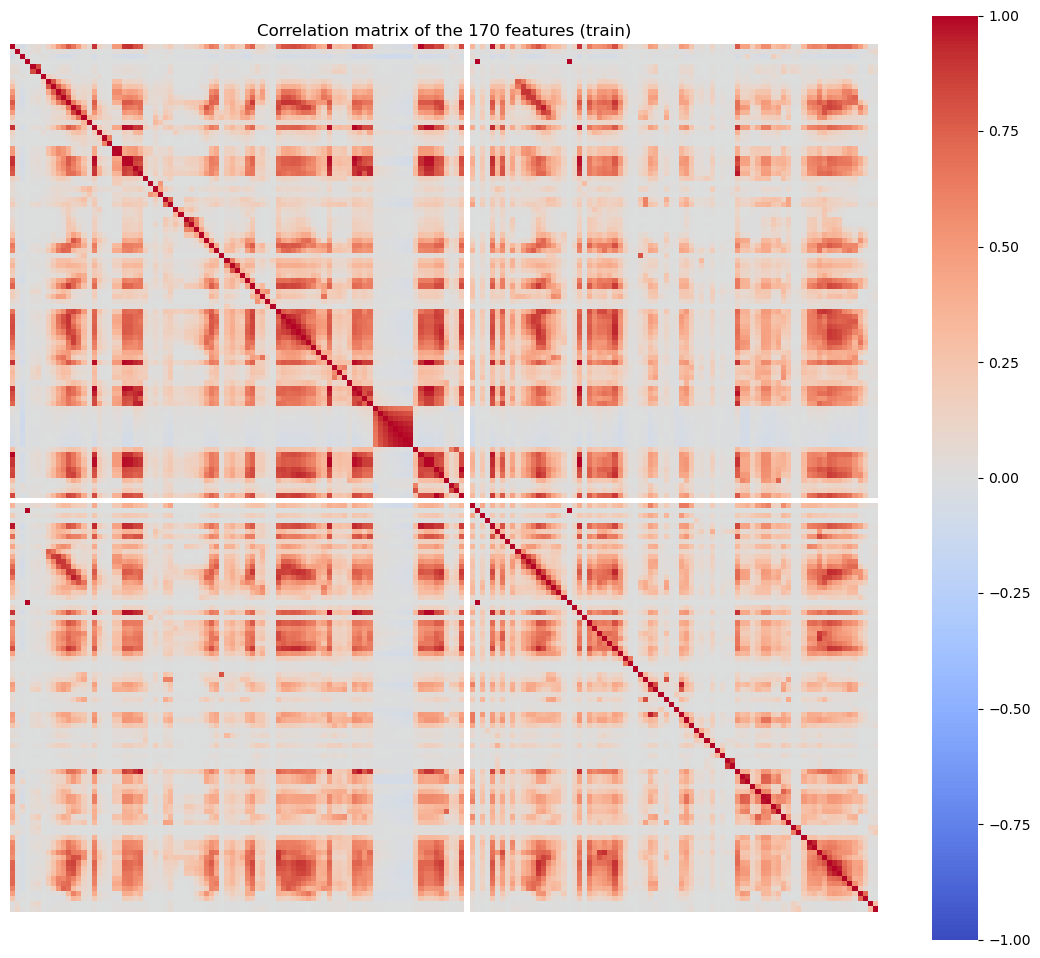

bv_000  cq_000    1.000000
bu_000  cq_000    1.000000
        bv_000    1.000000
cf_000  co_000    1.000000
ad_000  cf_000    1.000000
        co_000    1.000000
aa_000  bt_000    0.998774
ah_000  bg_000    0.997745
bb_000  bv_000    0.996258
        bu_000    0.996258
dtype: float64


In [13]:
corr = X_train.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, square=True, xticklabels=False, yticklabels=False)
plt.title('Correlation matrix of the 170 features (train)')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs.loc[pairs.abs().sort_values(ascending=False).head(10).index])

#### (iv) Make scatter plots and box plots

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


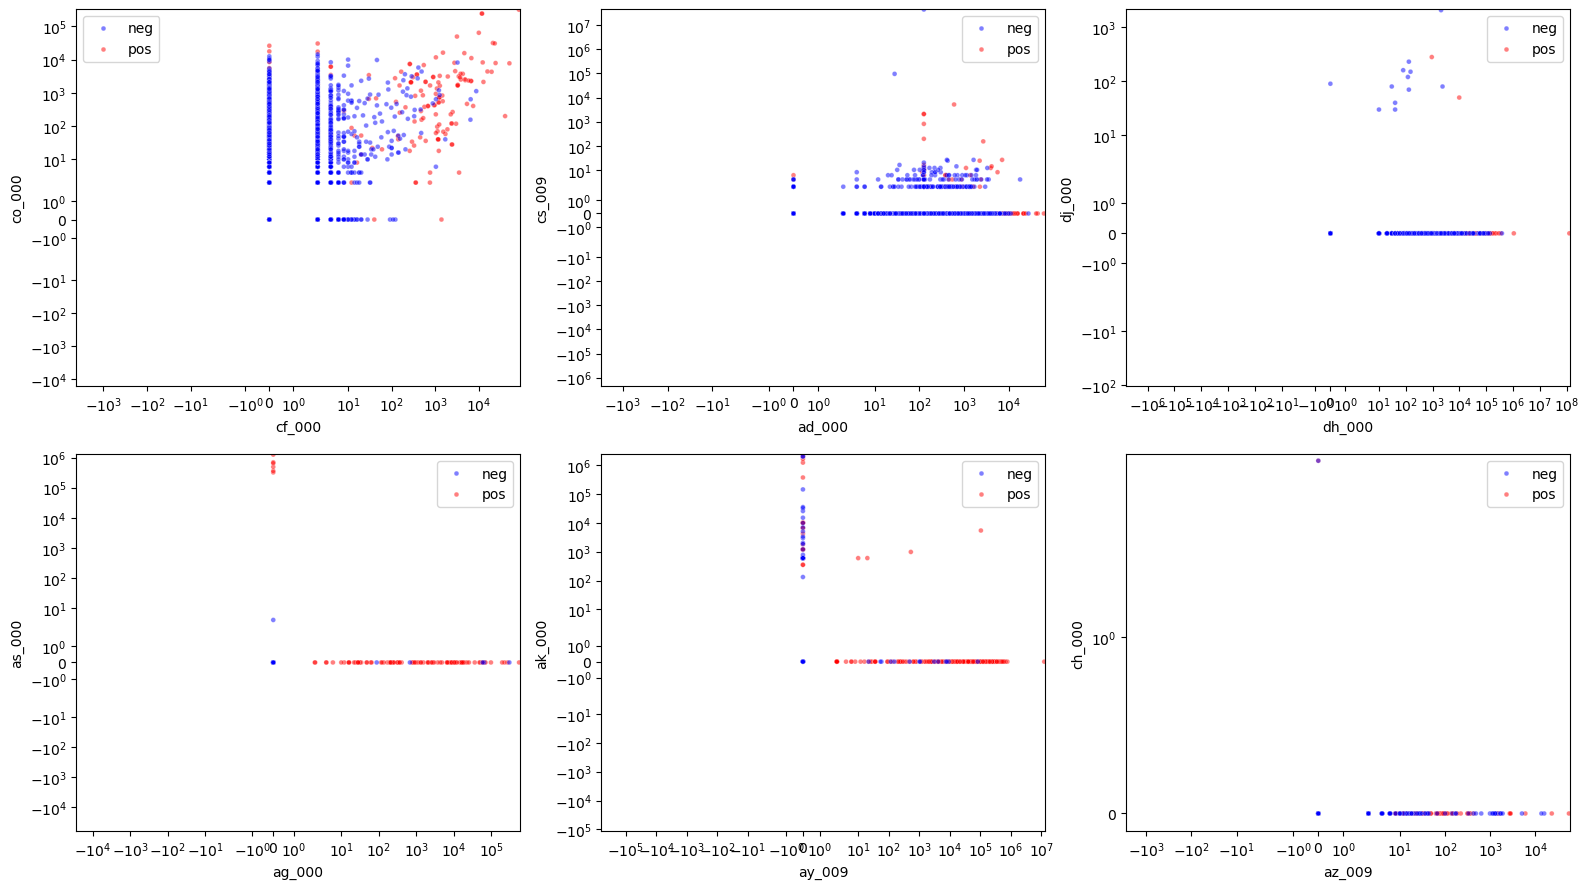

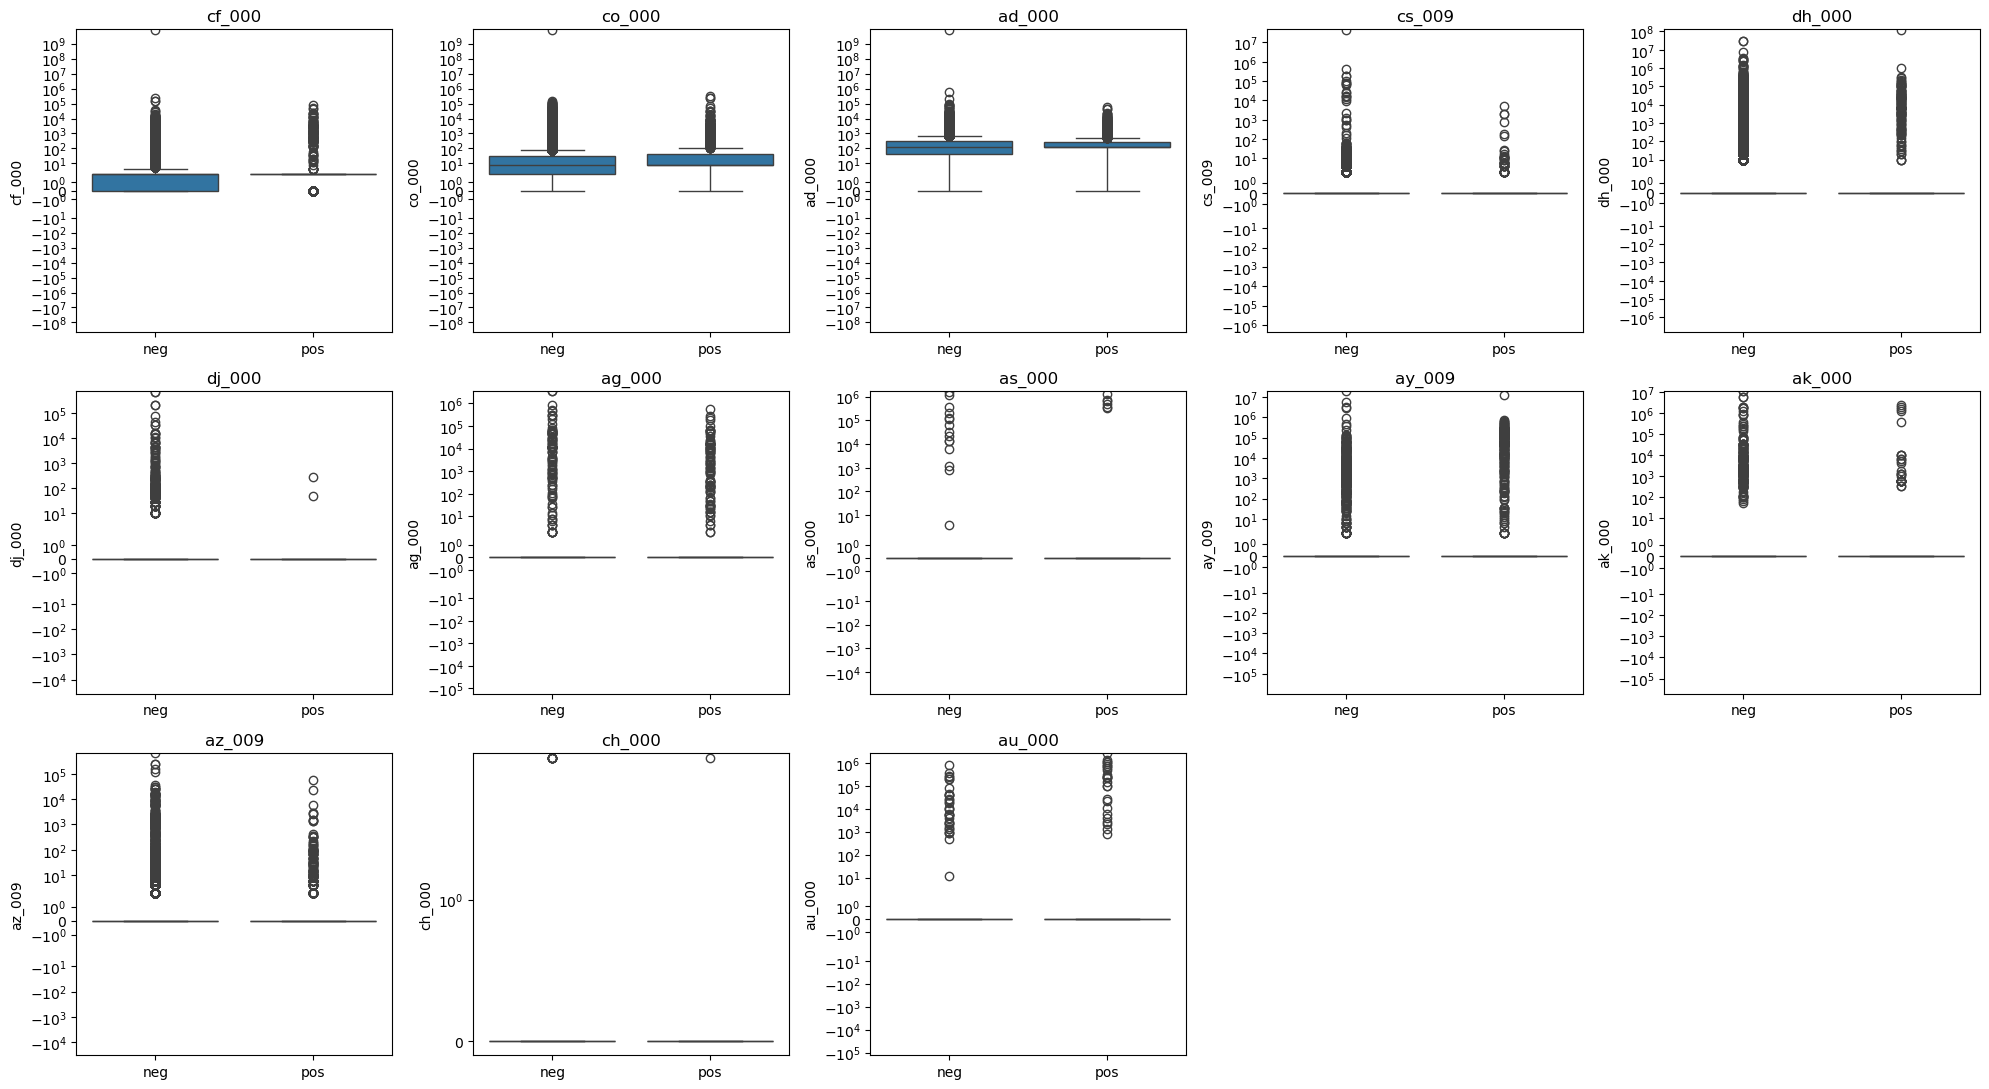

In [15]:
k = int(np.floor(np.sqrt(170)))
top = cv.head(k).index.tolist()
print(top)
cls = np.where(y_train == 1, 'pos', 'neg')

rng = np.random.default_rng(0)
idx = np.r_[np.where(y_train == 1)[0], rng.choice(np.where(y_train == 0)[0], 4000, replace=False)]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (a, b) in zip(axes.ravel(), [(top[i], top[i + 1]) for i in range(0, 12, 2)]):
    sns.scatterplot(x=X_train.loc[idx, a], y=X_train.loc[idx, b], hue=cls[idx],
                    hue_order=['neg', 'pos'], palette={'neg': 'blue', 'pos': 'red'},
                    s=12, alpha=0.5, ax=ax)
    ax.set_xscale('symlog'); ax.set_yscale('symlog')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, f in zip(axes.ravel(), top):
    sns.boxplot(x=cls, y=X_train[f], order=['neg', 'pos'], ax=ax)
    ax.set_yscale('symlog'); ax.set_title(f)
for ax in axes.ravel()[k:]:
    ax.axis('off')
plt.tight_layout(); plt.show()

#### (v) Is this data set imbalanced?

In [17]:
counts = pd.Series(y_train).value_counts().rename({0: 'neg', 1: 'pos'})
print(counts)
print("positive share, train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
print("imbalance ratio neg:pos =", int(counts['neg'] / counts['pos']), ": 1")

neg    59000
pos     1000
Name: count, dtype: int64
positive share, train: 0.0167 | test: 0.0234
imbalance ratio neg:pos = 59 : 1


The training set has 59,000 negative and 1,000 positive cases, so only 1.7% of the rows are positive and the ratio is 59 to 1. The test set is imbalanced in the same way, with 375 positive and 15,625 negative cases. The data set is therefore strongly imbalanced. A classifier that always predicts the negative class would reach 98.3% accuracy on the training set without detecting a single failure, so accuracy alone is not a good measure here, and the confusion matrix, the ROC curve and the AUC are needed.

### (c) Train a random forest

RF train: [[TN, FP], [FN, TP]] = [[59000, 0], [0, 1000]]
    misclassification = 0.0000, AUC = 1.0000, cost = 0
RF test: [[TN, FP], [FN, TP]] = [[15606, 19], [101, 274]]
    misclassification = 0.0075, AUC = 0.9944, cost = 50690


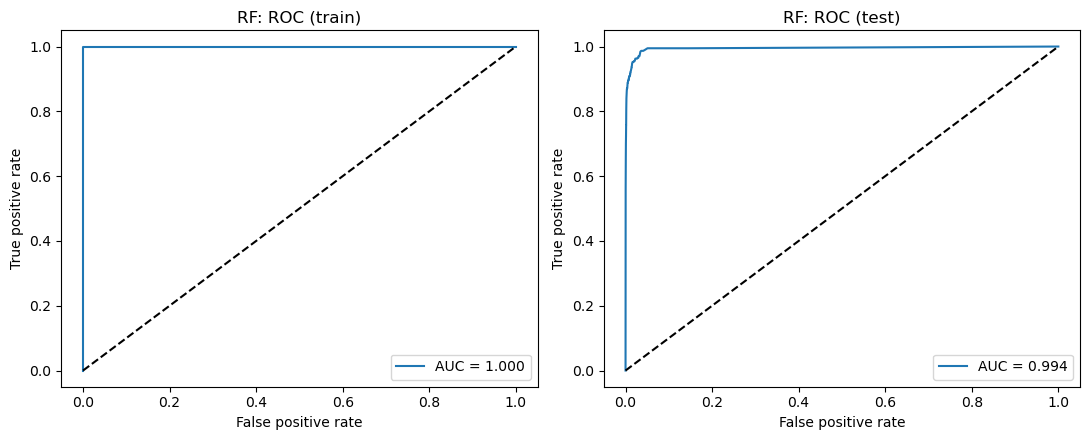

OOB error = 0.0058, test error = 0.0075


In [20]:
results = {}

def evaluate(model, name):
    out = {}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for (X, y, split), ax in zip([(X_train, y_train, 'train'), (X_test, y_test, 'test')], axes):
        proba = model.predict_proba(X)[:, 1]
        pred = (proba >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        auc = roc_auc_score(y, proba)
        err = (fp + fn) / len(y)
        print(f"{name} {split}: [[TN, FP], [FN, TP]] = [[{tn}, {fp}], [{fn}, {tp}]]")
        print(f"    misclassification = {err:.4f}, AUC = {auc:.4f}, cost = {10 * fp + 500 * fn}")
        fpr, tpr, _ = roc_curve(y, proba)
        ax.plot(fpr, tpr, label=f'AUC = {auc:.3f}'); ax.plot([0, 1], [0, 1], 'k--')
        ax.set_title(f'{name}: ROC ({split})')
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend()
        out[split] = dict(err=err, auc=auc, fp=fp, fn=fn, cost=10 * fp + 500 * fn)
    plt.tight_layout(); plt.show()
    results[name] = out

rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=0).fit(X_train, y_train)
evaluate(rf, 'RF')
print(f"OOB error = {1 - rf.oob_score_:.4f}, test error = {results['RF']['test']['err']:.4f}")

I trained a random forest with 300 trees and no correction for class imbalance. On the training set the confusion matrix is [[59000, 0], [0, 1000]], so the misclassification error is 0 and the AUC is 1.000. This only shows that the forest memorizes the training data, since the trees are grown to purity, and says nothing about new data.

On the test set the confusion matrix is [[15606, 19], [101, 274]]. There are 19 false positives and 101 false negatives, so the misclassification error is 0.0075 and the AUC is 0.994. The forest finds 274 of the 375 failures, a recall of 0.73, and 274 of its 293 positive predictions are correct, a precision of 0.94. The error is small mainly because 97.7% of the test cases are negative. The forest misses more than a quarter of the real failures, and each miss costs 500, so the total cost is 50,690.

The out-of-bag error is 0.0058, which is close to the test error of 0.0075. The OOB estimate is computed from trees that did not see the case, so it is an honest estimate that does not need a test set. It is a little lower than the test error, and the test set also has a higher share of positive cases than the training set, 2.3% against 1.7%, which leaves a little more room for errors.

### (d) Research class imbalance in random forest

Class imbalance in random forests is usually handled in one of these ways. Class weights make an error on the rare class count more in the split criterion and in the leaf votes, and the balanced_subsample option recomputes the weights inside each bootstrap sample. A balanced random forest draws every bootstrap sample with equal numbers of positive and negative cases, so each tree sees a balanced data set. Other options are to oversample the minority class, for example with SMOTE, to undersample the majority class, or to keep the forest as it is and lower the probability cut-off for the positive class.

I use class weights with the balanced_subsample option.

RF balanced train: [[TN, FP], [FN, TP]] = [[59000, 0], [0, 1000]]
    misclassification = 0.0000, AUC = 1.0000, cost = 0
RF balanced test: [[TN, FP], [FN, TP]] = [[15609, 16], [158, 217]]
    misclassification = 0.0109, AUC = 0.9934, cost = 79160


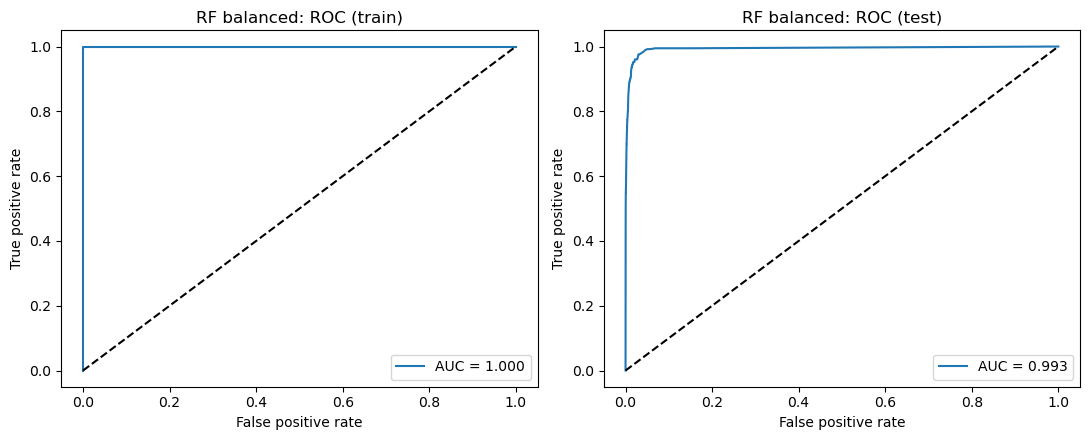

OOB error = 0.0074, test error = 0.0109


In [22]:
rf_bal = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                oob_score=True, n_jobs=-1, random_state=0).fit(X_train, y_train)
evaluate(rf_bal, 'RF balanced')
print(f"OOB error = {1 - rf_bal.oob_score_:.4f}, test error = {results['RF balanced']['test']['err']:.4f}")

I compensated for the imbalance with class weights, using the balanced_subsample option, and repeated the experiment of 1(c). The training result is still perfect, with a confusion matrix of [[59000, 0], [0, 1000]] and an AUC of 1.000.

On the test set the confusion matrix is [[15609, 16], [158, 217]], with a misclassification error of 0.0109 and an AUC of 0.993. Compared with 1(c), the false positives fell a little, from 19 to 16, but the false negatives rose from 101 to 158. The recall fell from 0.73 to 0.58 and the total cost rose from 50,690 to 79,160. The OOB error also rose, from 0.0058 to 0.0074, and the test error from 0.0075 to 0.0109. The OOB error is again below the test error.

So the class weights did not help here. The AUC is almost unchanged, 0.994 against 0.993, which means the forest ranks the cases about equally well, and the difference comes from how many cases end up above the 0.5 cut-off. With trees grown to purity the weights have little influence on the votes, which is one likely reason why this form of compensation did not raise the recall, although I did not test this. A forest trained on balanced samples, or a lower cut-off for the positive class, would be the next thing to try.

### (e) XGBoost and Model Trees

   reg_alpha  cv_error    cv_auc
0          0  0.005800  0.989692
1          1  0.005733  0.989963
2         10  0.006717  0.989644
3        100  0.011550  0.982118
best alpha: 1
XGB train: [[TN, FP], [FN, TP]] = [[58997, 3], [54, 946]]
    misclassification = 0.0009, AUC = 0.9997, cost = 27030
XGB test: [[TN, FP], [FN, TP]] = [[15601, 24], [95, 280]]
    misclassification = 0.0074, AUC = 0.9958, cost = 47740


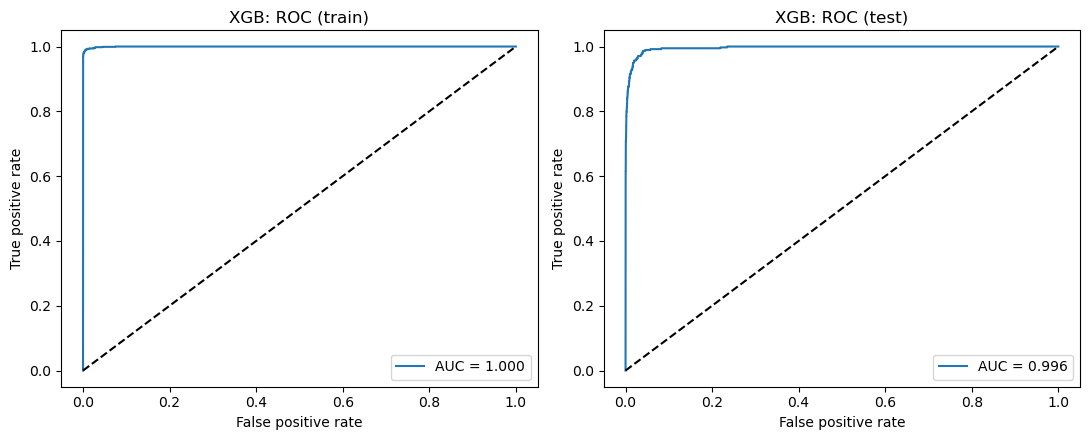

CV error = 0.0057, test error = 0.0074


In [23]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
alphas = [0, 1, 10, 100]
scoring = {'acc': 'accuracy', 'auc': 'roc_auc'}

def make_xgb():
    return XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8,
                         colsample_bytree=0.8, tree_method='hist', eval_metric='logloss',
                         random_state=0, n_jobs=-1)

grid_e = GridSearchCV(make_xgb(), {'reg_alpha': alphas}, cv=skf,
                      scoring=scoring, refit='acc').fit(X_train, y_train)
print(pd.DataFrame({'reg_alpha': alphas,
                    'cv_error': 1 - grid_e.cv_results_['mean_test_acc'],
                    'cv_auc': grid_e.cv_results_['mean_test_auc']}))
print("best alpha:", grid_e.best_params_['reg_alpha'])
evaluate(grid_e.best_estimator_, 'XGB')
print(f"CV error = {1 - grid_e.best_score_:.4f}, test error = {results['XGB']['test']['err']:.4f}")

For the XGBoost model with an L1 penalty on the leaf weights I used 200 trees of depth 4 and chose the penalty alpha by 5-fold stratified cross-validation, without compensating for the imbalance. The CV error is 0.0058 for alpha = 0, 0.0057 for alpha = 1, 0.0067 for alpha = 10 and 0.0116 for alpha = 100, and the CV AUC follows the same pattern. Alpha = 1 is best, and a very large penalty hurts. The difference between 0 and 1 is tiny.

With alpha = 1 the training confusion matrix is [[58997, 3], [54, 946]], so the training error is 0.0009 and the AUC is 1.000. Unlike the random forest, the boosted model does not fit the training data perfectly. On the test set the confusion matrix is [[15601, 24], [95, 280]], with an error of 0.0074, an AUC of 0.996 and a total cost of 47,740. It finds 280 of the 375 failures, a recall of 0.75.

The cross-validation error of 0.0057 is close to the test error of 0.0074. The test error is a little higher, which is expected because alpha was chosen on the cross-validation folds and the test set has more positive cases, 2.3% against 1.7%. Compared with the random forest of 1(c), the boosted model has about the same test error, 0.0074 against 0.0075, a slightly higher AUC and a slightly lower cost.

### (f) Use SMOTE to pre-process your data

The right way is to apply SMOTE only to the training part of each cross-validation fold. SMOTE is placed inside the pipeline, so in every fold the synthetic positive cases are created from the training fold only and the model is evaluated on the untouched validation fold. The test set is never resampled. The wrong way is to apply SMOTE to the whole training set first and then cross-validate. Then the validation folds contain synthetic points that were built from real positive cases of the training folds, and the training folds contain synthetic points built from the validation cases, so the validation error is far too optimistic.

   reg_alpha  cv_error    cv_auc
0          0  0.009267  0.987101
1          1  0.009333  0.987524
2         10  0.010717  0.986405
3        100  0.020033  0.984407
best alpha: 0
XGB + SMOTE train: [[TN, FP], [FN, TP]] = [[58756, 244], [43, 957]]
    misclassification = 0.0048, AUC = 0.9989, cost = 23940
XGB + SMOTE test: [[TN, FP], [FN, TP]] = [[15524, 101], [48, 327]]
    misclassification = 0.0093, AUC = 0.9947, cost = 25010


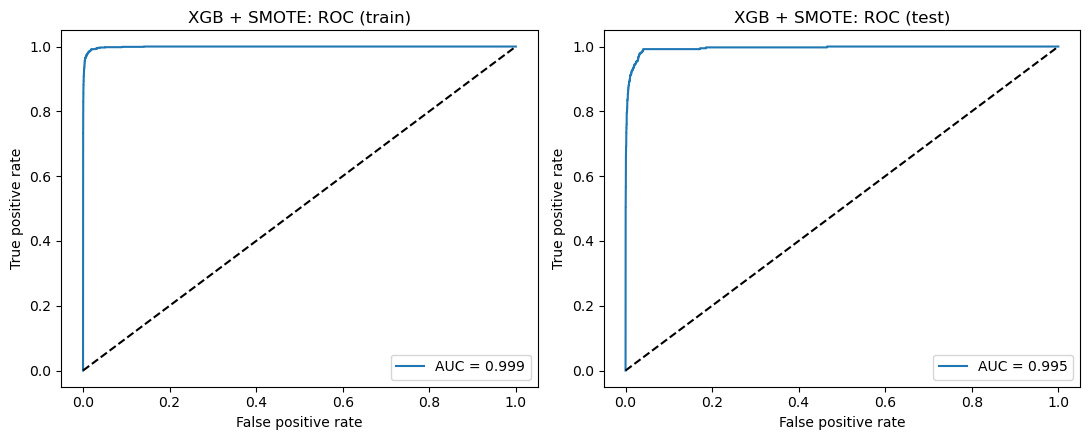

CV error = 0.0093, test error = 0.0093


,Model,Train error,Test error,Train AUC,Test AUC,Test FP,Test FN,Test cost
0,RF,0.000000,0.007500,1.000000,0.994422,19,101,50690
1,RF balanced,0.000000,0.010875,1.000000,0.993429,16,158,79160
2,XGB,0.000950,0.007437,0.999684,0.995774,24,95,47740
3,XGB + SMOTE,0.004783,0.009312,0.998934,0.994722,101,48,25010


In [25]:
smote_pipe = ImbPipeline([('smote', SMOTE(random_state=0)), ('xgb', make_xgb())])
grid_f = GridSearchCV(smote_pipe, {'xgb__reg_alpha': alphas}, cv=skf,
                      scoring=scoring, refit='acc').fit(X_train, y_train)
print(pd.DataFrame({'reg_alpha': alphas,
                    'cv_error': 1 - grid_f.cv_results_['mean_test_acc'],
                    'cv_auc': grid_f.cv_results_['mean_test_auc']}))
print("best alpha:", grid_f.best_params_['xgb__reg_alpha'])
evaluate(grid_f.best_estimator_, 'XGB + SMOTE')
print(f"CV error = {1 - grid_f.best_score_:.4f}, test error = {results['XGB + SMOTE']['test']['err']:.4f}")

pd.DataFrame([{'Model': n, 'Train error': r['train']['err'], 'Test error': r['test']['err'],
               'Train AUC': r['train']['auc'], 'Test AUC': r['test']['auc'],
               'Test FP': r['test']['fp'], 'Test FN': r['test']['fn'], 'Test cost': r['test']['cost']}
              for n, r in results.items()])

SMOTE is applied inside the pipeline, so in every fold the synthetic positive cases are created from the training part only. The CV error is 0.0093 for alpha = 0 and alpha = 1, 0.0107 for alpha = 10 and 0.0200 for alpha = 100, so alpha = 0 is chosen. After SMOTE the training data are balanced, and the final model is fitted on the whole resampled training set.

The confusion matrix on the original training data is [[58756, 244], [43, 957]]. On the test set it is [[15524, 101], [48, 327]], with an error of 0.0093, an AUC of 0.995 and a total cost of 25,010. The CV error of 0.0093 matches the test error of 0.0093. This is what we expect when SMOTE is done only inside the training folds, because the validation folds are real data and the estimate is not too optimistic.

Compared with the uncompensated XGBoost model of 1(e), SMOTE finds many more of the failures. The false negatives on the test set fall from 95 to 48, so the recall rises from 0.75 to 0.87, while the false positives rise from 24 to 101. The misclassification error gets worse, from 0.0074 to 0.0093, and the AUC is practically the same, 0.995 against 0.996, so SMOTE does not make the model rank the cases better. It moves the operating point toward the positive class. This pays off under the cost of the challenge, because a missed failure costs 500 and an unnecessary check costs 10, and the test cost falls from 47,740 to 25,010, almost by half. If only the error rate matters, the uncompensated model is better, and if missing a failure is the expensive mistake, SMOTE is better.

Over all four models, the lowest test error belongs to the uncompensated XGBoost and random forest, and the lowest cost to XGBoost with SMOTE.

## 2. ISLR 6.6.3

(a) iv. Steadily decrease. As s increases the constraint on the coefficients is relaxed, so the model becomes more flexible and fits the training data better, and the training RSS falls until it reaches the least squares value.
(b) ii. Decrease initially, and then eventually start increasing in a U shape. With s close to 0 the model is almost constant and underfits, so the test RSS is high. As s grows the test RSS falls, but when s is large the model overfits the training data and the test RSS rises again.
(c) iii. Steadily increase. A larger s gives a more flexible model, which has a higher variance.
(d) iv. Steadily decrease. A more flexible model has a lower bias, and the bias keeps falling as s grows.
(e) v. Remain constant. The irreducible error is the variance of the noise, which does not depend on the model.

## 3. ISLR 6.6.5

Since x_11 + x_21 = 0 and x_11 = x_12, x_21 = x_22, we can write x_11 = x_12 = a and x_21 = x_22 = -a. Also y_2 = -y_1.

(a) The ridge regression problem is to minimize
(y_1 - β_1 x_11 - β_2 x_12)^2 + (y_2 - β_1 x_21 - β_2 x_22)^2 + λ(β_1^2 + β_2^2).
With the values above both squared terms are equal to (y_1 - (β_1 + β_2) a)^2, so the problem is to minimize 2 (y_1 - (β_1 + β_2) a)^2 + λ(β_1^2 + β_2^2).

(b) The first term depends only on the sum s = β_1 + β_2. For a fixed s the penalty β_1^2 + β_2^2 is at least s^2 / 2, and it equals s^2 / 2 only when β_1 = β_2 = s / 2. Any solution with β_1 ≠ β_2 can therefore be improved by moving to β_1 = β_2 = s / 2, which keeps the first term and lowers the penalty. So the ridge estimates satisfy β_1 = β_2.

(c) The lasso problem is to minimize 2 (y_1 - (β_1 + β_2) a)^2 + λ(|β_1| + |β_2|).

(d) The first term again depends only on s = β_1 + β_2. The penalty satisfies |β_1| + |β_2| ≥ |s|, with equality exactly when β_1 and β_2 have the same sign, or one of them is zero. Let s* be the best value of the sum. Every pair with β_1 + β_2 = s* and both of the same sign reaches the same minimal objective, so the lasso solution is not unique. If s* > 0 the solutions are β_1 = t and β_2 = s* - t for any t between 0 and s*, and if s* < 0 they are all pairs with t between s* and 0.

## 4. ISLR 8.4.5

Majority vote: six of the ten estimates, 0.55, 0.6, 0.6, 0.65, 0.7 and 0.75, are above 0.5 and say Red, and four say Green, so the final classification is Red.
Average probability: the ten estimates sum to 4.5, so the mean is 0.45, which is below 0.5, and the final classification is Green.

## 5. ISLR 9.7.3

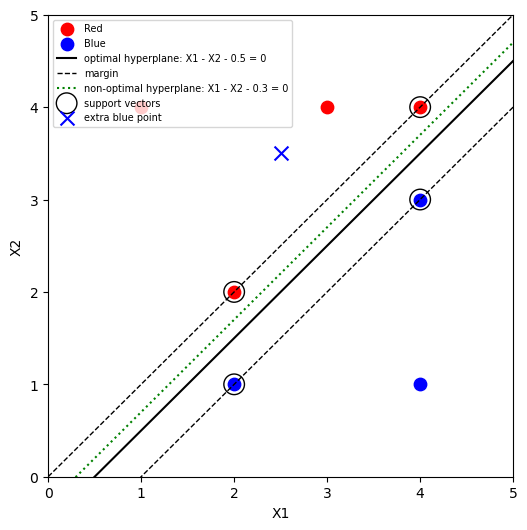

In [26]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
x = np.linspace(0, 5, 50)
plt.figure(figsize=(6, 6))
plt.scatter(*red.T, c='red', s=80, label='Red')
plt.scatter(*blue.T, c='blue', s=80, label='Blue')
plt.plot(x, x - 0.5, 'k-', label='optimal hyperplane: X1 - X2 - 0.5 = 0')
plt.plot(x, x, 'k--', lw=1, label='margin'); plt.plot(x, x - 1, 'k--', lw=1)
plt.plot(x, x - 0.3, 'g:', label='non-optimal hyperplane: X1 - X2 - 0.3 = 0')
plt.scatter([2, 4, 2, 4], [2, 4, 1, 3], s=220, facecolors='none', edgecolors='k', label='support vectors')
plt.scatter([2.5], [3.5], c='blue', marker='x', s=100, label='extra blue point')
plt.xlim(0, 5); plt.ylim(0, 5); plt.xlabel('X1'); plt.ylabel('X2')
plt.legend(fontsize=7); plt.show()

(a) The sketch is in the plot above. The red observations are (3,4), (2,2), (4,4) and (1,4), and the blue ones are (2,1), (4,3) and (4,1).
(b) The optimal separating hyperplane lies midway between the red points (2,2) and (4,4) and the blue points (2,1) and (4,3). It passes through (2, 1.5) and (4, 3.5), so its equation is X1 - X2 - 0.5 = 0.
(c) Classify to Red if 0.5 - X1 + X2 > 0, and to Blue otherwise. This gives β0 = 0.5, β1 = -1 and β2 = 1.
(d) The margin is the distance from the hyperplane to the closest observations, 0.5 / √2 ≈ 0.354, so the whole margin is about 0.707 wide. The margin boundaries are the dashed lines X2 = X1 and X2 = X1 - 1.
(e) The support vectors are the observations on the margin boundaries, (2,2) and (4,4) for Red and (2,1) and (4,3) for Blue.
(f) Observation 7 at (4,1) is not a support vector. It lies well outside the margin, and the maximal margin hyperplane depends only on the support vectors, so a slight movement of observation 7 that keeps it outside the margin does not change the hyperplane.
(g) A hyperplane that separates the two classes but is not optimal is X1 - X2 - 0.3 = 0, that is, classify to Red if 0.3 - X1 + X2 > 0. Its smallest distance to an observation is 0.3 / √2 ≈ 0.212, which is smaller than the optimal margin of 0.354.
(h) Add a blue observation at (2.5, 3.5). It lies inside the triangle formed by the red points (1,4), (2,2) and (4,4), so no hyperplane can separate the two classes.